<a href="https://colab.research.google.com/github/Orliluq/harness2_tutorial/blob/main/harness2_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Harness² de Google Research: tutorial práctico en Google Colab

**Objetivo:** entender cómo Harness² mejora el sistema que rodea a un agente de IA y recorrer una demostración real del repositorio, paso a paso.

> **Importante:** este cuaderno tiene dos partes distintas:
> 1. Una mini-simulación didáctica, escrita para explicar la idea con una hoja de transacciones.
> 2. La demostración oficial `harness2-demo`, que ejecuta el flujo interno de adaptación con editores deterministas locales y **no necesita credenciales de modelos**.
>
> La demo no es un benchmark con Gemini, Claude u otro modelo: sirve para explorar la mecánica de Harness². Las ejecuciones de benchmarks reales requieren más configuración y pueden generar costes.

**Fuentes principales**
- [Repositorio oficial de Harness²](https://github.com/google-research/harness2)
- [Paper en arXiv](https://arxiv.org/abs/2610.14224)
- [Guía de instalación oficial](https://github.com/google-research/harness2/blob/main/docs/SETUP.md)
- [Guía oficial de experimentos](https://github.com/google-research/harness2/blob/main/docs/EXPERIMENTS.md)

## 1. La idea en palabras sencillas

Un **modelo** es el motor. El **harness** es el equipo que lo rodea para que pueda trabajar: instrucciones, herramientas, memoria, habilidades, subagentes y reglas de ejecución.

Harness² intenta mejorar ese equipo sin volver a entrenar los pesos del modelo. Para la tarea actual usa un ciclo **Propose–Probe–Compose**:

1. **Propose (proponer):** plantea cambios al harness.
2. **Probe (probar):** ejecuta las alternativas en la misma tarea y observa qué ocurrió.
3. **Compose (componer):** combina la evidencia de esas ejecuciones en una versión refinada.

Después hay un segundo ciclo: conserva aprendizajes que cuentan con evidencia para ayudar a adaptar tareas futuras. Es como arreglar una herramienta para el trabajo de hoy y además anotar qué reparación funcionó para la próxima vez.

## 2. Ejemplo didáctico: una hoja de transacciones

Imagina que un agente debe conciliar un pequeño libro contable. La tabla contiene cargos positivos y abonos negativos. El código original tiene una regla equivocada: suma solo importes positivos. El agente entrega un total, pero omite los abonos.

Vamos a comparar la lógica inicial con una corrección. Este ejemplo manual es didáctico; después ejecutaremos la demo oficial del proyecto, que también usa un ejemplo de conciliación de transacciones.

In [1]:
from decimal import Decimal

libros = {
    "libro_1": [Decimal("100.25"), Decimal("-20.10"), Decimal("5.00")],
    "libro_2": [Decimal("35.50"), Decimal("-10.25"), Decimal("-5.00")],
}

def total_original(importes):
    # Error: descarta cualquier importe negativo.
    return sum((x for x in importes if x > 0), Decimal("0"))

def total_corregido(importes):
    # Corrección: suma todos los movimientos, con su signo.
    return sum(importes, Decimal("0"))

for nombre, importes in libros.items():
    print(nombre)
    print("  Total original:", f"{total_original(importes):.2f}")
    print("  Total correcto:", f"{total_corregido(importes):.2f}")

libro_1
  Total original: 105.25
  Total correcto: 85.15
libro_2
  Total original: 35.50
  Total correcto: 20.25


### ¿Qué hemos observado?

El primer resultado puede parecer razonable, pero no representa el saldo neto porque ignora los importes negativos. La comparación entre ambas ejecuciones da una pista concreta: el filtro `if x > 0` es el responsable de excluir los abonos.

En el lenguaje de Harness², una hipótesis sería quitar ese filtro, probar el cambio con la misma tarea y observar la diferencia. En un entorno real, las alternativas y la selección las gestiona el flujo del framework; aquí hemos aislado la idea para que sea fácil de entender.

## 3. Preparar el entorno para la demostración oficial

En el menú de Colab, selecciona **Entorno de ejecución → Ejecutar todas** o ejecuta las celdas una a una. La instalación usa Python 3.12 dentro de un entorno aislado con `uv`, como recomienda el repositorio.

Si una celda de instalación falla por cambios en la imagen de Colab o por dependencias externas, revisa el mensaje de error y la [guía oficial de instalación](https://github.com/google-research/harness2/blob/main/docs/SETUP.md). No guardes tokens ni claves en un notebook público.

In [2]:
# Clona el repositorio oficial. Si ya existe en esta sesión, elimina la carpeta
# /content/harness2 antes de volver a ejecutar esta celda.
%cd /content
!git clone --depth 1 https://github.com/google-research/harness2.git

/content
Cloning into 'harness2'...
remote: Enumerating objects: 151, done.
remote: Counting objects: 100% (151/151), done.
remote: Compressing objects: 100% (122/122), done.
remote: Total 151 (delta 16), reused 93 (delta 14), pack-reused 0 (from 0)
Receiving objects: 100% (151/151), 6.77 MiB | 13.28 MiB/s, done.
Resolving deltas: 100% (16/16), done.


In [3]:
%cd /content/harness2
!python --version
!curl -LsSf https://astral.sh/uv/install.sh | sh

import os
os.environ["PATH"] = os.path.expanduser("~/.local/bin") + os.pathsep + os.environ.get("PATH", "")
!uv --version

/content/harness2
Python 3.13.16
downloading uv 0.13.4 x86_64-unknown-linux-gnu
installing to /usr/local/bin
  uv
  uvx
everything's installed!
uv 0.13.4 (x86_64-unknown-linux-gnu)


In [4]:
# Harness² requiere Python >=3.12 y <3.14.
!uv python install 3.12
!uv venv --python 3.12 .venv
!uv pip install --python .venv/bin/python -e '.[render]'

Installed Python 3.12.15 in 1.81s
 + cpython-3.12.15-linux-x86_64-gnu (python3.12)
Using CPython 3.12.15
Creating virtual environment at: .venv
Activate with: source .venv/bin/activate
Resolved 8 packages in 346ms
Prepared 8 packages in 2.01s
Installed 8 packages in 17ms
 + et-xmlfile==2.0.0
 + harness2==0.1.0 (from file:///content/harness2)
 + lxml==6.1.3
 + openpyxl==3.1.5
 + pillow==13.0.0
 + python-pptx==1.0.2
 + typing-extensions==4.16.0
 + xlsxwriter==3.2.9


## 4. Ejecutar `harness2-demo`: el flujo real, sin claves de API

La siguiente celda ejecuta el comando oficial de demostración con `k=2` y ambos modos. El repositorio indica que esta demo usa editores deterministas y ejecuciones locales de Python; no llama a un modelo remoto ni necesita credenciales de modelo.

- **Modo paralelo:** explora varias alternativas y compone una mejora a partir de la evidencia compartida.
- **Modo secuencial:** realiza pasos de refinamiento consecutivos, llevando la evidencia al siguiente paso.

In [5]:
!./.venv/bin/harness2-demo --output /content/harness2-demo --k 2 --mode both

  [accounting] 1/2 ok           ledger-1
  [accounting] 2/2 ok           ledger-2
Local demo: 2 tasks completed; 0 failed. /content/harness2-demo/demo.json


## 5. Inspeccionar los resultados guardados

Harness² guarda archivos de ejecución e información sobre las decisiones tomadas. La demo imprime la ruta del informe `demo.json`. Vamos a abrirlo y listar algunos de los artefactos que generó.

In [6]:
from pathlib import Path
import json

informe = Path('/content/harness2-demo/demo.json')
print("¿Existe el informe?", informe.exists())

if informe.exists():
    datos = json.loads(informe.read_text(encoding='utf-8'))
    print("Claves de primer nivel:", list(datos.keys()))
    print(json.dumps(datos, indent=2, ensure_ascii=False)[:10000])
else:
    print("No se encontró demo.json. Revisa la salida de la celda anterior.")

¿Existe el informe? True
Claves de primer nivel: ['domain', 'n_tasks', 'seed', 'done', 'failed', 'tasks', 'execution_count', 'editor_calls']
{
  "domain": "accounting",
  "n_tasks": 2,
  "seed": null,
  "done": 2,
  "failed": 0,
  "tasks": [
    {
      "task": "ledger-1",
      "status": "ok",
      "library_entries_before": {
        "agg": 0,
        "seq": 0
      }
    },
    {
      "task": "ledger-2",
      "status": "ok",
      "library_entries_before": {
        "agg": 1,
        "seq": 1
      }
    }
  ],
  "execution_count": 28,
  "editor_calls": 32
}


In [7]:
raiz = Path('/content/harness2-demo')
for ruta in sorted(raiz.rglob('*')):
    if ruta.is_file():
        print(ruta.relative_to(raiz))

base/LongTermMEMORY.md
base/guardrails.md
base/scripts/summarize.py
base/systemprompt.md
base/tool_descriptions/tool_guidance.md
demo.json
executions/demo-oc-agg2/ledger-1/agg1/answer.txt
executions/demo-oc-agg2/ledger-1/agg1/trajectory.md
executions/demo-oc-agg2/ledger-1/agg2/answer.txt
executions/demo-oc-agg2/ledger-1/agg2/trajectory.md
executions/demo-oc-agg2/ledger-1/base1/answer.txt
executions/demo-oc-agg2/ledger-1/base1/trajectory.md
executions/demo-oc-agg2/ledger-1/base2/answer.txt
executions/demo-oc-agg2/ledger-1/base2/trajectory.md
executions/demo-oc-agg2/ledger-1/dom1/answer.txt
executions/demo-oc-agg2/ledger-1/dom1/trajectory.md
executions/demo-oc-agg2/ledger-1/dom2/answer.txt
executions/demo-oc-agg2/ledger-1/dom2/trajectory.md
executions/demo-oc-agg2/ledger-1/inv1/answer.txt
executions/demo-oc-agg2/ledger-1/inv1/trajectory.md
executions/demo-oc-agg2/ledger-1/inv2/answer.txt
executions/demo-oc-agg2/ledger-1/inv2/trajectory.md
executions/demo-oc-agg2/ledger-2/agg1/answer.txt


## 6. Conectar lo observado con las dos recursiones

| Nivel | Pregunta que responde | En el ejemplo de conciliación |
|---|---|---|
| **Recursión a nivel de tarea** | ¿Qué cambio mejora el harness para esta tarea? | Detectar que el filtro de positivos descarta abonos; probar una variante y comparar la salida. |
| **Recursión a nivel de mejora del harness** | ¿Qué lección respaldada por evidencia conviene conservar? | Si el mismo tipo de tarea aparece otra vez, recordar que una conciliación debe contemplar cargos y abonos. |

La segunda fila no significa que el sistema tenga memoria perfecta ni que cada lección vaya a generalizar a todo contexto. Se trata de experiencia registrada por dominio que puede orientar refinamientos posteriores; conviene revisar la evidencia.

In [9]:
from pathlib import Path

demo_path = Path('/content/harness2/harness2/demo.py')
if demo_path.exists():
    print(demo_path.read_text(encoding='utf-8'))
else:
    print('No se encontró el archivo demo.py en la ruta esperada.')

# Copyright 2026 Google LLC
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

"""A deterministic local adapter for exercising the real adaptation workflow."""

from __future__ import annotations

import csv
import subprocess
import sys
from decimal import Decimal
from pathlib import Path

from .core import tree
from .core.proposer import Proposer, Reply
from .core.spec import BenchPrompts, BenchSpec, ChannelSpec
from .substrate.opencode import OpencodeSubstrate

BASE_SCRIPT = """import csv
import 

Al analizar el código de `harness2/demo.py`, podemos ver exactamente cómo se simulan y estructuran los dos flujos bajo un esquema adaptativo determinista local:

1. **El Proponente Determinista (`DemoProposer`)**
En lugar de un modelo de lenguaje real (como Gemini o Claude), la demo implementa un proponente determinista programado en Python (`DemoProposer(Proposer)`):

- **Propuestas (`else`):** Modifica el archivo de la herramienta objetivo (`scripts/summarize.py`) eliminando de forma explícita el filtro que descarta los importes negativos (` if amount > 0`), permitiendo simular cómo se soluciona el error.
- **Generación de Experiencia (`experience.`):** Compara si el script resultante en la carpeta de prueba (`harness/scripts/summarize.py`) difiere del de base. Si cambió, redacta de forma estructurada una etiqueta <experience> que incluye la pista (*cue*), la lección aprendida (*lesson*), la evidencia empírica observada y un nivel de confianza alto.
- **Selección del Candidato Exitoso (`select.`):** Automatiza la decisión leyendo el archivo de datos original (`ledger.csv`) para calcular el saldo neto real y selecciona de forma determinista la hipótesis cuyo resultado de ejecución coincide exactamente con el valor real.

2. Relación con los Modos Paralelo y Secuencial
En Modo Paralelo, los diferentes candidatos (`inv1`, `inv2`, `dom1`, `dom2`, etc., visibles en la estructura de directorios del reporte) se generan, evalúan y guardan en paralelo de manera independiente.
En **Modo Secuencial**, el `DemoProposer` encadena estos pasos recursivos secuencialmente, acumulando las respuestas e iterando progresivamente sobre el mismo espacio de trabajo (`workspace`) para generar candidatos sucesivos.

## 7. ¿Qué significan `--k`, `parallel` y `sequential`?

`--k` controla el presupuesto de recursión a nivel de tarea. En la guía del proyecto:

- `--k 1`: un paso Propose–Probe–Compose.
- `--k K --mode parallel`: explora candidatos en paralelo y compone mejoras a partir del conjunto de evidencias.
- `--k K --mode sequential`: realiza `K` pasos consecutivos, reutilizando el harness refinado y la evidencia acumulada.

Más pasos pueden ayudar, pero también aumentan el trabajo y, en experimentos con modelos remotos, el coste. No conviene empezar con un benchmark completo.

In [8]:
import json
from pathlib import Path

# Cargamos el archivo de resultados para extraer datos reales de la demo si existen
informe_path = Path('/content/harness2-demo/demo.json')
datos_demo = {}
if informe_path.exists():
    datos_demo = json.loads(informe_path.read_text(encoding='utf-8'))

# Resumen estructurado de las diferencias entre ambos modos
resumen_modos = """
### Diferencias entre los modos de ejecución en Harness²:

1. **Modo Paralelo (`--mode parallel`):**
   - **Funcionamiento:** Explora y evalúa múltiples candidatos o propuestas de cambios de manera simultánea en el mismo paso.
   - **Fórmula:** Realiza un paso Propose–Probe-Compose donde combina la evidencia de todos los rollouts concurrentes para estructurar el harness refinado.
   - **Ventaja:** Es más rápido en entornos con paralelización real y evita sesgos de orden secuencial al evaluar alternativas de forma independiente en un mismo nivel.

2. **Modo Secuencial (`--mode sequential`):**
   - **Funcionamiento:** Realiza pasos de refinamiento consecutivos uno tras otro (iteraciones sucesivas).
   - **Fórmula:** El resultado y la evidencia acumulada de la iteración anterior sirven de base directa para la siguiente propuesta del ciclo.
   - **Ventaja:** Permite un refinamiento incremental profundo y acumulativo, ideal cuando los cambios complejos requieren construirse sobre correcciones previas.
"""

print(resumen_modos)
if datos_demo:
    print(f"-> Datos de la ejecución actual: Se completaron {datos_demo.get('done', 0)} tareas utilizando ambos métodos en la simulación.")


### Diferencias entre los modos de ejecución en Harness²:

1. **Modo Paralelo (`--mode parallel`):**
   - **Funcionamiento:** Explora y evalúa múltiples candidatos o propuestas de cambios de manera simultánea en el mismo paso.
   - **Fórmula:** Realiza un paso Propose–Probe-Compose donde combina la evidencia de todos los rollouts concurrentes para estructurar el harness refinado.
   - **Ventaja:** Es más rápido en entornos con paralelización real y evita sesgos de orden secuencial al evaluar alternativas de forma independiente en un mismo nivel.

2. **Modo Secuencial (`--mode sequential`):**
   - **Funcionamiento:** Realiza pasos de refinamiento consecutivos uno tras otro (iteraciones sucesivas).
   - **Fórmula:** El resultado y la evidencia acumulada de la iteración anterior sirven de base directa para la siguiente propuesta del ciclo.
   - **Ventaja:** Permite un refinamiento incremental profundo y acumulativo, ideal cuando los cambios complejos requieren construirse sobre correccio

In [11]:
# Para ejecutar estos comandos de consola en una celda de Python, debemos anteponer '!'
# y utilizar los ejecutables instalados dentro del entorno virtual (.venv)

!./.venv/bin/harness2-setup lab
!./.venv/bin/harness2-check --bench lab
!./.venv/bin/harness2 --bench lab --k 1 --mode parallel --only-domains antitrust-competition --max-tasks 1
!./.venv/bin/harness2-judge --bench lab --k 1 --mode parallel
!./.venv/bin/harness2-report --bench lab --k 1 --mode parallel

git init -q /content/harness2/dependencies/opencode
git -C /content/harness2/dependencies/opencode remote add origin https://github.com/anomalyco/opencode.git
git -C /content/harness2/dependencies/opencode fetch --depth 1 origin 23fb5e0516c99ac04a1aa46c193efda2e1b9bb24
remote: Enumerating objects: 4832, done.
remote: Counting objects: 100% (4832/4832), done.
remote: Compressing objects: 100% (4062/4062), done.
remote: Total 4832 (delta 640), reused 4180 (delta 623), pack-reused 0 (from 0)
Receiving objects: 100% (4832/4832), 49.51 MiB | 29.63 MiB/s, done.
Resolving deltas: 100% (640/640), done.
From https://github.com/anomalyco/opencode
 * branch            23fb5e0516c99ac04a1aa46c193efda2e1b9bb24 -> FETCH_HEAD
git -C /content/harness2/dependencies/opencode checkout --detach FETCH_HEAD
HEAD is now at 23fb5e0 release: v1.14.18
git -C /content/harness2/dependencies/opencode apply --check /content/harness2/third_party/patches/opencode-compat.diff
git -C /content/harness2/dependencies/open

In [17]:
# Ejecutar la demo local oficial con un presupuesto de recursión k=2 en ambos modos
!./.venv/bin/harness2-demo --output /content/harness2-demo --k 2 --mode both

  [accounting] 1/2 skipped      ledger-1
  [accounting] 2/2 skipped      ledger-2
Local demo: 2 tasks completed; 0 failed. /content/harness2-demo/demo.json


# **Workflow de Harness²**

El diagrama incluye los dos modos de recursión, el ciclo **Propose → Probe → Compose**, la adopción del harness mejorado y la actualización de la biblioteca de experiencias.

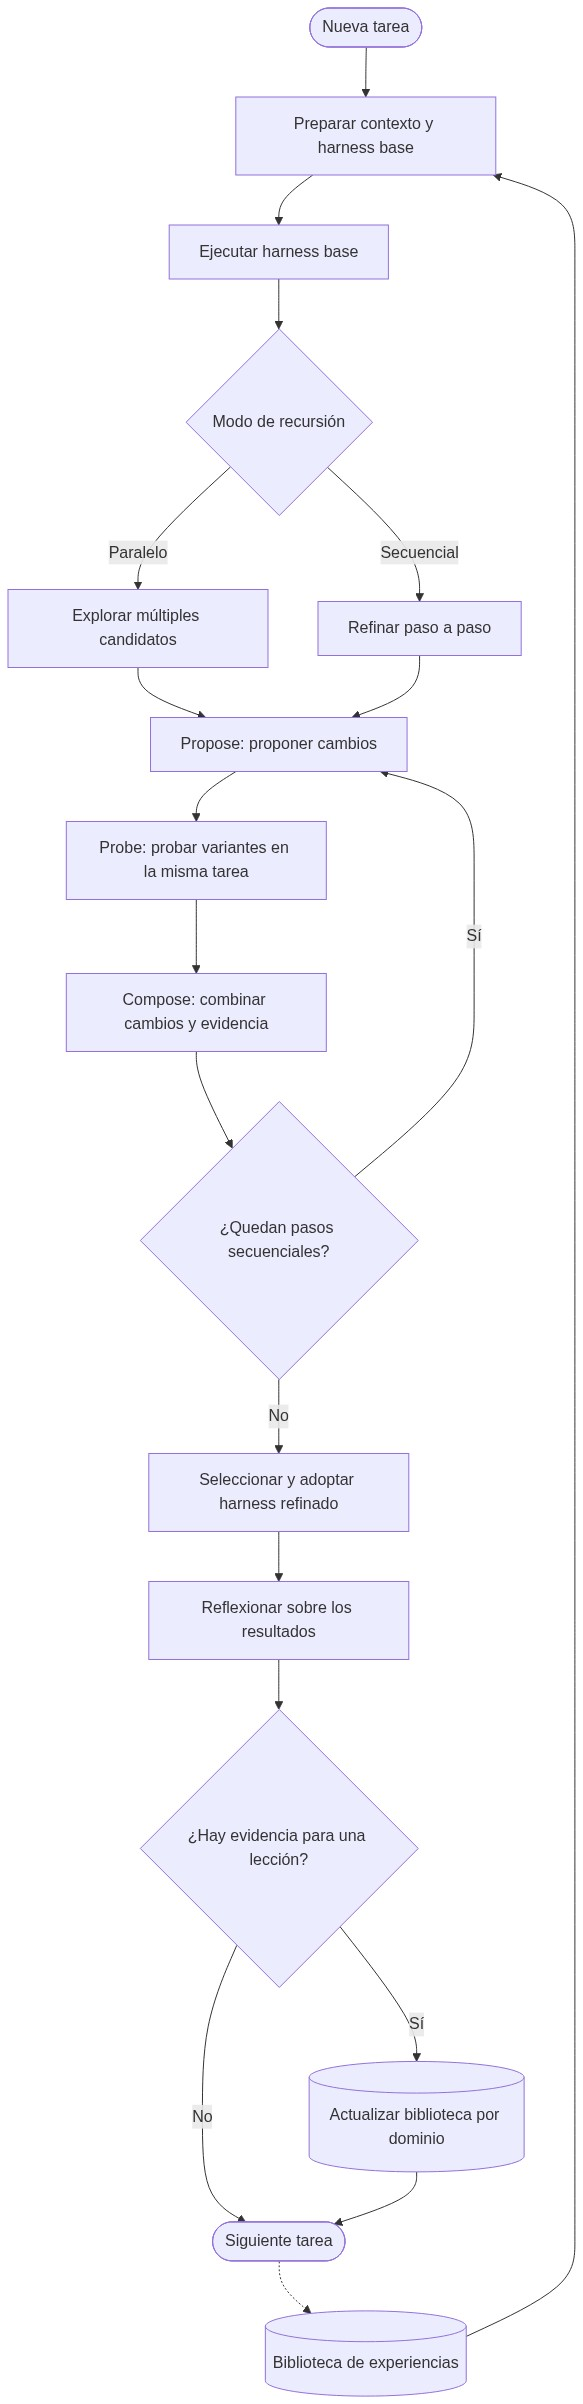

Diagrama guardado en: /content/harness2_workflow.png


In [14]:
import base64
from pathlib import Path
import requests
from IPython.display import Image, display, Markdown

mermaid = r'''flowchart TD
    A(["Nueva tarea"]) --> B["Preparar contexto y harness base"]
    L[("Biblioteca de experiencias")] --> B
    B --> C["Ejecutar harness base"]
    C --> D{"Modo de recursión"}

    D -->|"Paralelo"| E["Explorar múltiples candidatos"]
    D -->|"Secuencial"| F["Refinar paso a paso"]

    E --> G["Propose: proponer cambios"]
    F --> G
    G --> H["Probe: probar variantes en la misma tarea"]
    H --> I["Compose: combinar cambios y evidencia"]
    I --> J{"¿Quedan pasos secuenciales?"}
    J -->|"Sí"| G
    J -->|"No"| K["Seleccionar y adoptar harness refinado"]

    K --> M["Reflexionar sobre los resultados"]
    M --> N{"¿Hay evidencia para una lección?"}
    N -->|"Sí"| O[("Actualizar biblioteca por dominio")]
    N -->|"No"| P(["Siguiente tarea"])
    O --> P
    P -.-> L'''

# Mermaid Ink acepta el código Mermaid codificado en Base64 URL-safe.
payload = base64.urlsafe_b64encode(mermaid.encode('utf-8')).decode('ascii')
url = f'https://mermaid.ink/img/{payload}'
response = requests.get(url, timeout=60)
response.raise_for_status()

png_path = Path('/content/harness2_workflow.png')
png_path.write_bytes(response.content)

display(Image(filename=str(png_path)))
print(f'Diagrama guardado en: {png_path}')

In [15]:
from google.colab import files
files.download('/content/harness2_workflow.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. ¿Cómo pasar de la demo a un benchmark real?

La demo local no requiere credenciales de modelos; los benchmarks reales sí tienen requisitos adicionales, que dependen del benchmark elegido. El repositorio documenta:

- Linux y Python 3.12 para ejecuciones de benchmark.
- `uv`, Node.js 20 o posterior y Google Cloud CLI.
- Configuración de un proyecto y modelos con Vertex AI, además de autenticación de Google Cloud (u otra ruta admitida).
- Dependencias específicas para cada benchmark; por ejemplo, LAB requiere Pandoc y Poppler y WorkBuddy-Bench requiere Docker.

**No ejecutes un benchmark grande sin revisar antes selección de tareas, acceso del agente a la red y costes de modelos.** El repositorio advierte que los benchmarks publicados pueden exponer criterios de evaluación a un ejecutor con acceso a Internet; para evaluar con rigor hay que aplicar las restricciones de red recomendadas por el proyecto.

Documentación: [SETUP.md](https://github.com/google-research/harness2/blob/main/docs/SETUP.md), [BENCHMARKS.md](https://github.com/google-research/harness2/blob/main/docs/BENCHMARKS.md) y [EXPERIMENTS.md](https://github.com/google-research/harness2/blob/main/docs/EXPERIMENTS.md).

## 9. Ideas clave para recordar

1. Harness² no es un modelo nuevo: mejora el sistema de ejecución que rodea al modelo, manteniendo fijos sus pesos.
2. Su ciclo interno es **proponer → probar → componer**, guiado por la comparación entre ejecuciones.
3. El ciclo externo conserva aprendizajes respaldados por evidencia para orientar tareas posteriores.
4. La demo oficial en Colab permite recorrer la mecánica sin claves de API; no debe confundirse con los benchmarks que usan modelos reales.
5. Más iteraciones no garantizan mejores resultados: hay que medir, revisar costes, comprobar la calidad de las salidas y mantener límites de seguridad.

**Siguiente paso:** consulta el [README oficial](https://github.com/google-research/harness2) y el [paper de Harness²](https://arxiv.org/abs/2610.14224) para profundizar en la arquitectura y los resultados experimentales.